# Núcleo 1 — Serie histórica de coparticipación (2003-2025)

Acá miro cómo evolucionó la coparticipación federal que recibieron las provincias
argentinas, en pesos corrientes y en pesos constantes (deflactados por IPC), con foco
en Córdoba.

El rango cubierto es 2003-2025 — lo amplié desde 2016-2025 al conseguir una fuente de
IPC confiable para 2003-2015 (Fundación Norte y Sur / Orlando Ferreres). No llega a
1990, que era la idea original, porque no existe una fuente de montos nominales de
coparticipación para 1990-2002; el detalle de ese empalme y de esa limitación está en
`docs/methodology.md`.

Defino "coparticipación" como la coparticipación Ley 23.548 bruta (incluida la parte que
la Ley 26.075 afecta a Financiamiento Educativo), más la compensación del Consenso Fiscal
(Ley 27.429, desde 2018), más, hasta 2017, las asignaciones específicas de Ganancias que
el Consenso Fiscal pasó a repartir por la Ley 23.548. Con esa definición la serie no
tiene quiebres cuando Hacienda cambia la forma de informar, y coincide con lo que
registra la propia Córdoba (Núcleo 4). Dejo afuera otros regímenes de Recursos de Origen
Nacional como el IVA de la Ley 23.966, Bienes Personales o combustibles. El porqué de
cada decisión está en `docs/methodology.md`.

Trabajo sobre `data/processed/coparticipacion_real.csv`, generado por
`scripts/process_coparticipacion.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# Paleta y estilo (validados con el validador de la skill de dataviz del proyecto:
# 4 colores categóricos en orden fijo, pasan los chequeos de daltonismo para líneas).
COLOR_CORDOBA = "#2a78d6"      # slot 1 - azul
COLOR_BUENOS_AIRES = "#eb6834" # slot 2 - naranja
COLOR_SANTA_FE = "#1baf7a"     # slot 3 - aqua
COLOR_MENDOZA = "#eda100"      # slot 4 - amarillo

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "text.color": INK_PRIMARY,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
})

BASE_DIR = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
FIGURES_DIR = BASE_DIR / "output" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(BASE_DIR / "data" / "processed" / "coparticipacion_real.csv")
df.head()


,provincia,anio,monto_nominal,ipc_promedio_anual,monto_real_base2016
0,Buenos Aires,2003,3534.2179,7.653077,42090.902105
1,Buenos Aires,2004,5063.0036,7.991016,57748.042701
2,Buenos Aires,2005,6177.2050,8.761483,64260.697259
3,Buenos Aires,2006,7528.0907,9.716292,70617.984679
4,Buenos Aires,2007,9841.3698,11.106101,80765.325161


## 1. Verificación rápida de los datos

Espero 552 filas: 24 jurisdicciones (23 provincias + CABA) × 23 años (2003-2025).
`monto_nominal` está en millones de pesos corrientes; `monto_real_base2016`, en
millones de pesos constantes de 2016 (promedio del año).

In [2]:
print(f"Filas: {len(df)}  |  Provincias: {df['provincia'].nunique()}  |  Años: {df['anio'].min()}-{df['anio'].max()}")
assert len(df) == 552, "Se esperaban 552 filas (24 jurisdicciones x 23 años)"
df.describe()


Filas: 552  |  Provincias: 24  |  Años: 2003-2025


,anio,monto_nominal,ipc_promedio_anual,monto_real_base2016
count,552.000000,5.520000e+02,552.000000,552.000000
mean,2014.000000,2.306570e+05,861.692484,20120.019931
std,6.639266,8.562244e+05,2171.958535,20296.904784
min,2003.000000,1.798141e+02,7.653077,2141.502843
25%,2008.000000,2.038377e+03,13.653147,9169.869508
50%,2014.000000,9.658495e+03,51.931048,14816.231858
75%,2020.000000,6.766536e+04,330.541683,22240.577344
max,2025.000000,1.299461e+07,8966.166533,148263.193119


## 2. Evolución real de la coparticipación de Córdoba

En pesos constantes (base 2016), para sacar el efecto de la inflación y ver si a la
provincia le quedó más o menos poder de compra a lo largo del tiempo.

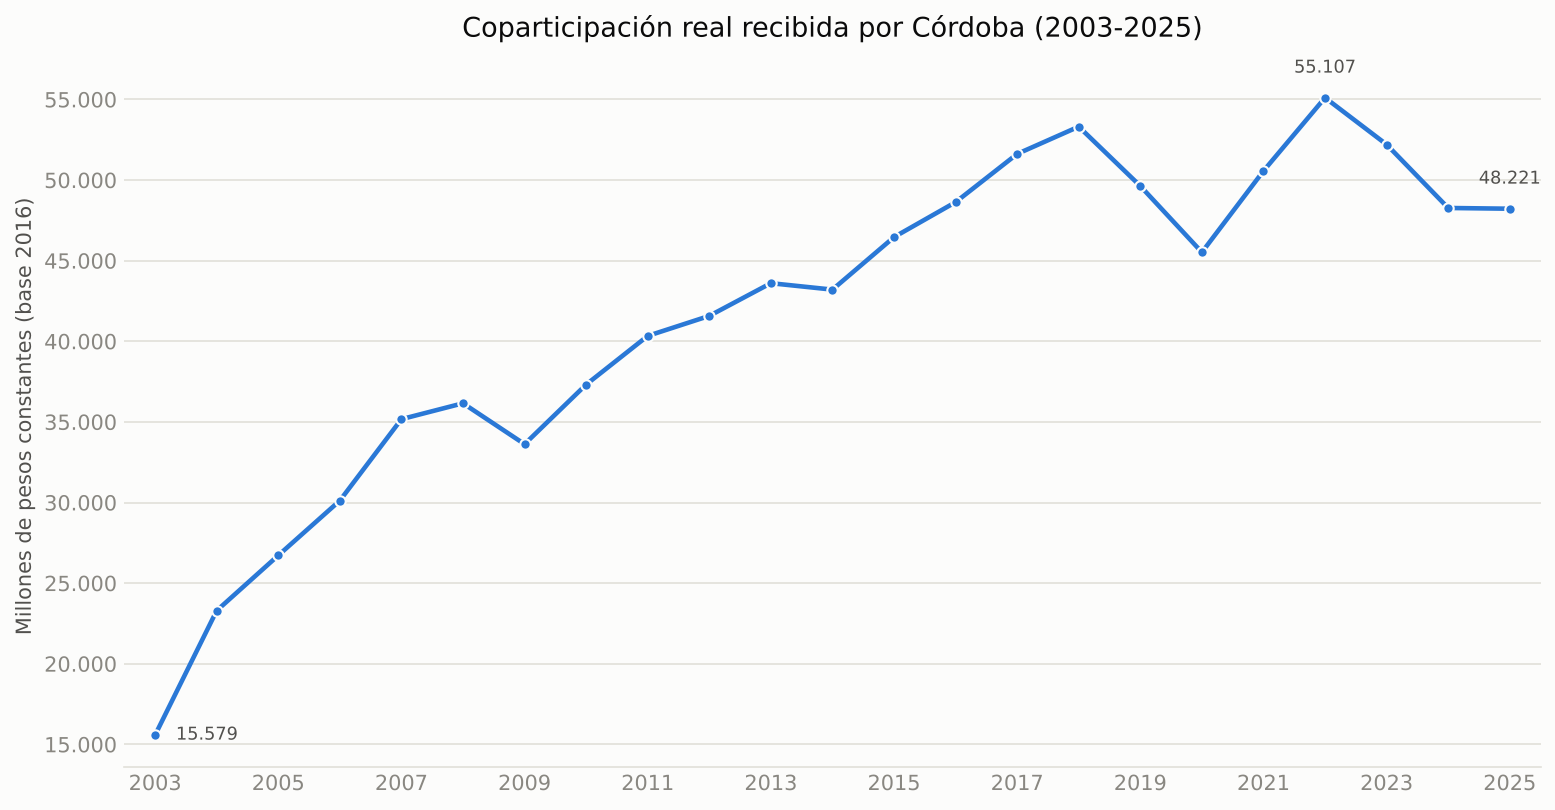

In [3]:
cordoba = df[df["provincia"] == "Córdoba"].sort_values("anio")

fig, ax = plt.subplots(figsize=(10.5, 5.5), dpi=150)
ax.plot(
    cordoba["anio"], cordoba["monto_real_base2016"],
    color=COLOR_CORDOBA, linewidth=2.2, marker="o", markersize=5,
    markerfacecolor=COLOR_CORDOBA, markeredgecolor=SURFACE, markeredgewidth=1,
)

# Etiquetas directas selectivas: primer punto, mínimo, máximo y último punto.
idx_max = cordoba["monto_real_base2016"].idxmax()
idx_min = cordoba["monto_real_base2016"].idxmin()
for idx in sorted(set([cordoba.index[0], idx_min, idx_max, cordoba.index[-1]])):
    row = cordoba.loc[idx]
    ax.annotate(
        f"{row['monto_real_base2016']:,.0f}".replace(",", "."),
        (row["anio"], row["monto_real_base2016"]),
        textcoords="offset points",
        xytext=((10, 0) if idx == cordoba.index[0] else (0, 10)),
        ha=("left" if idx == cordoba.index[0] else "center"),
        va=("center" if idx == cordoba.index[0] else "bottom"),
        fontsize=8.5, color=INK_SECONDARY,
    )

ax.set_title("Coparticipación real recibida por Córdoba (2003-2025)", fontsize=13, color=INK_PRIMARY, pad=14)
ax.set_ylabel("Millones de pesos constantes (base 2016)", fontsize=10)
ax.set_xlabel("")
ax.set_xlim(2002.5, 2025.5)
ax.set_xticks(range(2003, 2026, 2))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
plt.setp(ax.get_xticklabels(), rotation=0)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "cordoba_evolucion_real_2003_2025.png", dpi=300, facecolor=SURFACE)
plt.show()


La coparticipación real de Córdoba creció fuerte entre 2003 y 2008 (recuperación
pos-crisis 2001-2002), cayó en 2009 (crisis financiera internacional), volvió a crecer
hasta 2013 y tuvo una leve baja en 2014. Entre 2015 y 2018 sigue subiendo, cae en
2019-2020 (recesión y pandemia), llega a su punto más alto de toda la serie en 2022
(\$55.107 millones de 2016) y vuelve a caer en 2023-2025, consistente con el ajuste
fiscal de esos años a nivel nacional. En pesos constantes, 2025 (\$48.221 millones)
queda 12,5% por debajo del pico de 2022, más o menos en el nivel de 2016, y 3,1 veces
por encima de 2003. Ese múltiplo hay que leerlo con cuidado: 2003 todavía era un año de
crisis, y solo en 2004 la serie subió un 50% real. Contra 2004, la suba hasta 2025 es de
2,1 veces.

## 3. Comparativo: Córdoba vs. provincias de referencia

La comparo contra Buenos Aires, Santa Fe y Mendoza. Ojo: esto es en niveles absolutos
de pesos (no per cápita), así que Buenos Aires —la provincia más poblada del país— se
ve muy por encima solo por su tamaño. La comparación por habitante, con la población del
Censo 2022, está en el Núcleo 5.

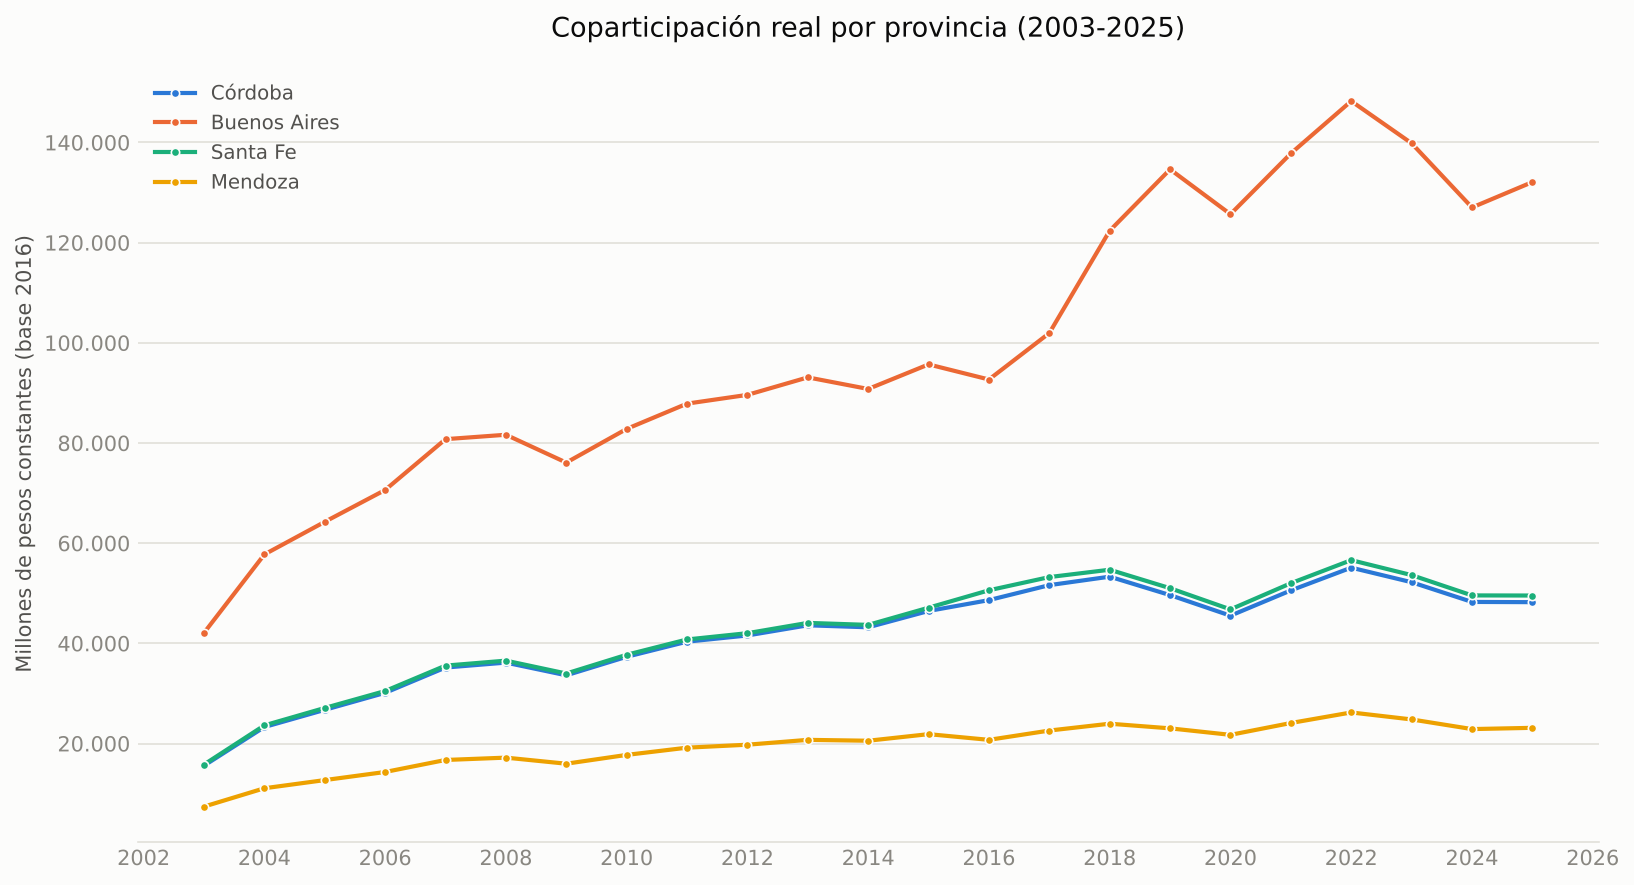

In [4]:
provincias_referencia = ["Córdoba", "Buenos Aires", "Santa Fe", "Mendoza"]
colores = {
    "Córdoba": COLOR_CORDOBA,
    "Buenos Aires": COLOR_BUENOS_AIRES,
    "Santa Fe": COLOR_SANTA_FE,
    "Mendoza": COLOR_MENDOZA,
}

fig, ax = plt.subplots(figsize=(11, 6), dpi=150)
for provincia in provincias_referencia:
    serie = df[df["provincia"] == provincia].sort_values("anio")
    ax.plot(
        serie["anio"], serie["monto_real_base2016"],
        color=colores[provincia], linewidth=2, marker="o", markersize=4,
        markerfacecolor=colores[provincia], markeredgecolor=SURFACE, markeredgewidth=0.8,
        label=provincia,
    )

ax.set_title("Coparticipación real por provincia (2003-2025)", fontsize=13, color=INK_PRIMARY, pad=14)
ax.set_ylabel("Millones de pesos constantes (base 2016)", fontsize=10)
ax.set_xlabel("")
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
legend = ax.legend(frameon=False, loc="upper left", fontsize=9.5)
for text in legend.get_texts():
    text.set_color(INK_SECONDARY)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "comparativo_provincias_real_2003_2025.png", dpi=300, facecolor=SURFACE)
plt.show()


## 4. Comparativo en términos relativos (indexado, 2003 = 100)

El gráfico anterior compara niveles absolutos, así que Buenos Aires domina solo por su
tamaño, no porque haya *crecido* más que las demás. Para ver eso, indexo cada serie a
su propio valor de 2003 (=100) y comparo las trayectorias relativas en un solo eje —
no es per cápita (eso está en el Núcleo 5), pero neutraliza la diferencia de escala
entre provincias.

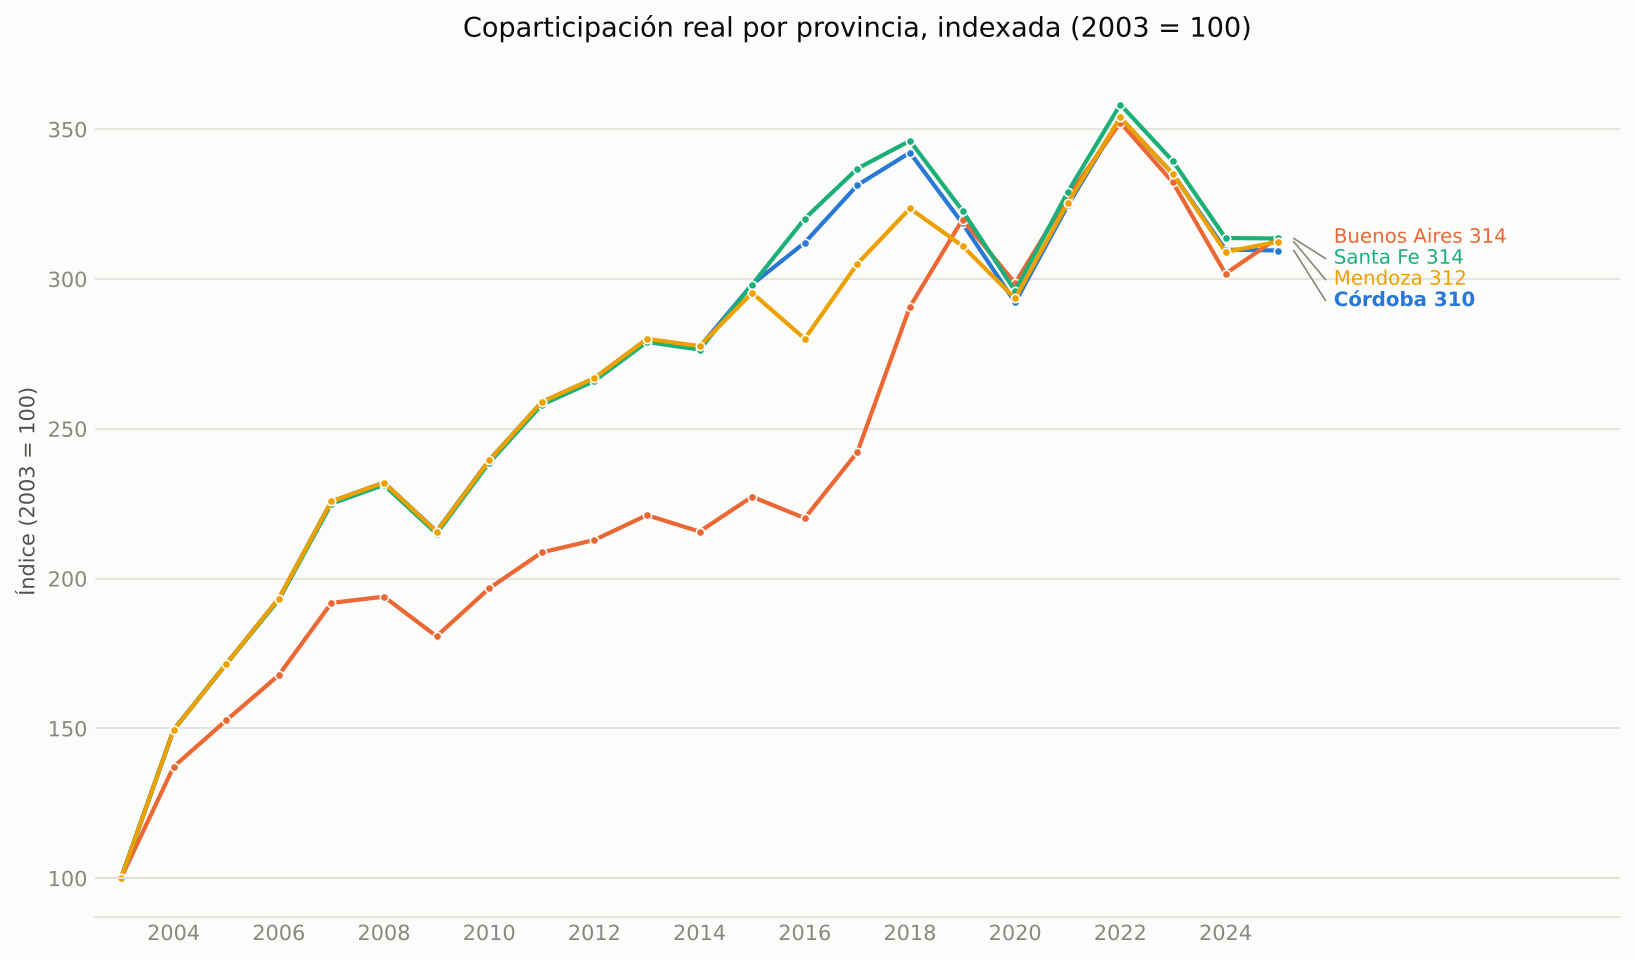

In [5]:
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=150)
indexado_final = {}
for provincia in provincias_referencia:
    serie = df[df["provincia"] == provincia].sort_values("anio").set_index("anio")["monto_real_base2016"]
    base_2003 = serie.loc[2003]
    indexado = serie / base_2003 * 100
    indexado_final[provincia] = indexado.loc[2025]
    ax.plot(
        indexado.index, indexado.values,
        color=colores[provincia], linewidth=2, marker="o", markersize=4,
        markerfacecolor=colores[provincia], markeredgecolor=SURFACE, markeredgewidth=0.8,
        label=provincia,
    )

# Etiquetas directas en el extremo derecho -- como los 4 valores finales quedan muy
# cerca (310-314), se espacian verticalmente para que no se pisen (nunca apilar
# etiquetas encimadas: ver marks-and-anatomy.md), con una línea guía fina hacia el
# punto real cuando el valor se desplazó de su posición natural.
orden = sorted(indexado_final.items(), key=lambda kv: kv[1], reverse=True)
ax.set_xlim(2002.5, 2031.5)
min_gap = 7  # puntos de índice mínimos entre etiquetas consecutivas
etiquetas_y = []
for _, valor in orden:
    y = valor if not etiquetas_y else min(valor, etiquetas_y[-1] - min_gap)
    etiquetas_y.append(y)

for (provincia, valor_real), y_etiqueta in zip(orden, etiquetas_y):
    if abs(y_etiqueta - valor_real) > 1:
        ax.plot([2025.3, 2025.9], [valor_real, y_etiqueta], color=INK_MUTED, linewidth=0.8, zorder=1)
    ax.annotate(
        f"{provincia} {valor_real:,.0f}",
        (2025.9, y_etiqueta),
        xytext=(4, 0), textcoords="offset points", ha="left", va="center",
        fontsize=9.5, color=colores[provincia], fontweight=("bold" if provincia == "Córdoba" else "normal"),
    )

ax.axhline(100, color=GRID_COLOR, linewidth=1)
ax.set_title("Coparticipación real por provincia, indexada (2003 = 100)", fontsize=13, color=INK_PRIMARY, pad=14)
ax.set_ylabel("Índice (2003 = 100)", fontsize=10)
ax.set_xlabel("")
ax.set_xticks(range(2004, 2026, 2))  # no extender ticks al espacio en blanco reservado para las etiquetas
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "comparativo_provincias_indexado_2003_2025.png", dpi=300, facecolor=SURFACE)
plt.show()


Las cuatro terminan 2025 entre 310 y 314 puntos (multiplicaron su coparticipación real
de 2003 unas 3,1 veces), y Córdoba y Santa Fe siguen trayectorias casi idénticas todo el
período. Hay dos desvíos en el camino. Buenos Aires se queda atrás entre 2004 y 2017
porque su Fondo del Conurbano estuvo congelado en un monto nominal fijo, y alcanza al
resto desde 2019, después del Consenso Fiscal. Mendoza se separa de Córdoba y Santa Fe
en 2016-2018: esas dos provincias dejaron de sufrir antes el descuento del 15% para la
ANSES (Núcleo 5). Fuera de esos cambios de reglas, el
patrón responde a la dinámica agregada del régimen (cuánto crece la masa total
distribuida), no a que a una provincia le vaya sistemáticamente mejor o peor que a
otra. El Núcleo 5 hace esta comparación para las 24 jurisdicciones.

## 5. Conclusiones y próximos pasos

- Córdoba y Santa Fe siguen una trayectoria prácticamente idéntica (recuperación
  2003-2008, caída en 2009, crecimiento hasta 2013, suba 2015-2018, caída 2019-2020, pico
  en 2022, caída 2023-2025), Mendoza también salvo en 2016-2018, y las cuatro provincias
  terminan 2025 entre 310 y 314 puntos indexados a 2003=100. El patrón responde a la dinámica agregada del
  régimen más que a algo específico de cada provincia.
- Buenos Aires recibe montos absolutos muy superiores al resto por ser la provincia
  más poblada. En términos relativos se quedó atrás entre 2004 y 2017 (Fondo del
  Conurbano congelado) y desde 2019 no se distingue del resto. En niveles no es
  comparable sin ajustar por población o por otra base: el Núcleo 2 lo compara con el
  PBG y el Núcleo 5, por habitante.
- Limitaciones a tener en cuenta (con el detalle completo en `docs/methodology.md`):
  - El rango 2003-2025 depende, para 2003-2015, de un IPC empalmado con una fuente
    privada (Fundación Norte y Sur / Orlando Ferreres) para el tramo 2007-2015, porque
    el IPC oficial de esos años quedó desacreditado por la intervención del INDEC. Esa
    fuente tiene además una limitación propia que no pude resolver: no logré verificar
    el contenido exacto de su nota "Ver metodología". Además, el IPC oficial
    actual arranca en diciembre de 2016, así que el promedio de 2016 lo estimo a partir
    del promedio oficial de 2017 y la variación 2017 de esa misma fuente privada.
  - No llega a 1990 porque no hay una fuente de montos nominales de coparticipación
    por provincia anterior a 2003.
  - La definición de "coparticipación" que uso excluye otros regímenes de Recursos de
    Origen Nacional (IVA de la Ley 23.966, Bienes Personales, combustibles, etc.).